# **Sales prediction - Neual Networks**

In [ ]:
import datetime
import importlib
import itertools
import math
import os
import random
import warnings
import holidays
import matplotlib.pyplot as plt
import neuralforecast.auto as na
import neuralforecast.models as m
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import eda
import training
import visuals
from copy import deepcopy
from datetime import timedelta
from itertools import chain, combinations
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MAE, MAPE, RMSE
from ray import tune
from ray.tune.search.optuna import OptunaSearch
from scipy import stats
from sklearn.metrics import make_scorer, mean_absolute_percentage_error
from sklearn.model_selection import (
    TimeSeriesSplit,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    LabelEncoder,
    MinMaxScaler,
    OneHotEncoder,
    PowerTransformer,
    StandardScaler,
)
from sktime.split import SlidingWindowSplitter
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch, het_white
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf
from utilsforecast.plotting import plot_series
from utilsforecast.preprocessing import fill_gaps

importlib.reload(eda)
importlib.reload(training)
importlib.reload(visuals)

warnings.filterwarnings('ignore')

pd.set_option('display.float_format', '{:.4f}'.format)

%matplotlib inline

In [ ]:
import logging
logger = logging.getLogger('cmdstanpy')
logger.addHandler(logging.NullHandler())
logger.propagate = False
logger.setLevel(logging.CRITICAL)

# Pytorch
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)

# Ray
logging.getLogger("ray").setLevel(logging.ERROR)



# **1. Loading and exploration of the dataset**

**Dataset description:**

Train and test datasets contain following columns:


*	ID - an Id that represents a (Shop, Item) tuple within the test set
*	shop_id - unique identifier of a shop
*	item_id - unique identifier of a product
*	item_cnt_day - number of products sold. Negative values mean returns
*	item_price - current price of an item
*	date  
*	date_block_num - a consecutive month number, used for convenience. January 2013 is 0, February 2013 is 1,..., October 2015 is 33





In [ ]:
# Loading train data to parquet file
sales = pd.read_csv('sales_train.csv')
sales.to_parquet('sales_train.gzip', compression='gzip')
sales = pd.read_parquet('sales_train.gzip')

In [ ]:
sales.head(20)

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.0000,1.0000
1,03.01.2013,0,25,2552,899.0000,1.0000
2,05.01.2013,0,25,2552,899.0000,-1.0000
3,06.01.2013,0,25,2554,1709.0500,1.0000
4,15.01.2013,0,25,2555,1099.0000,1.0000
5,10.01.2013,0,25,2564,349.0000,1.0000
6,02.01.2013,0,25,2565,549.0000,1.0000
7,04.01.2013,0,25,2572,239.0000,1.0000
8,11.01.2013,0,25,2572,299.0000,1.0000
9,03.01.2013,0,25,2573,299.0000,3.0000


In [ ]:
sales['date'] = pd.to_datetime(sales['date'], format = '%d.%m.%Y')

In [ ]:
sales.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2935849 entries, 0 to 2935848
Data columns (total 6 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   date            2935849 non-null  datetime64[ns]
 1   date_block_num  2935849 non-null  int64         
 2   shop_id         2935849 non-null  int64         
 3   item_id         2935849 non-null  int64         
 4   item_price      2935849 non-null  float64       
 5   item_cnt_day    2935849 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(3)
memory usage: 134.4 MB


#### Id features exploration - item_id, shop_id

In [ ]:
# Counts per store and item - train

print(f'Unique stores count: {len(sales["shop_id"].unique())}\nUnique items count: {len(sales["item_id"].unique())}')

Unique stores count: 60
Unique items count: 21807


In [ ]:
# Creating ID column
sales['unique_id'] = sales.apply(lambda x: str(x['shop_id'])+'_'+str(x['item_id']), axis = 1)
sales['unique_id'] = LabelEncoder().fit_transform(sales['unique_id'])

In [ ]:
sales[['date_block_num','shop_id','item_id','unique_id']] = sales[['date_block_num','shop_id','item_id','unique_id']].astype('object')
#sales['date_block_num'] = sales['date_block_num'].cat.as_ordered()

In [ ]:
# Summary statistics - categorical columns

sales[sales.select_dtypes('object').columns].describe()

,date_block_num,shop_id,item_id,unique_id
count,2935849,2935849,2935849,2935849
unique,34,60,21807,424124
top,11,31,20949,146521
freq,143246,235636,31340,867


There are 60 unique shops and around 22,000 unique items in the dataset. Overally there are almost 3,000,000 of unique shop-item time series.

In [ ]:
# Checking counts of observations in the each series

In [ ]:
counts_per_id = sales.groupby('unique_id').count()[['date']]
counts_per_id = counts_per_id.rename(columns={'date':'count'})

In [ ]:
counts_per_id.describe()

,count
count,424124.0000
mean,6.9221
std,15.6943
min,1.0000
25%,1.0000
50%,3.0000
75%,7.0000
max,867.0000


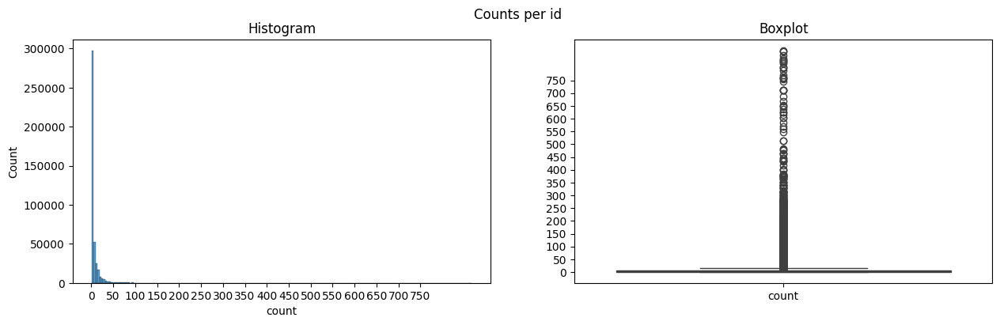

In [ ]:
# Plotting counts per id


fig, ax = plt.subplots(1,2, figsize = (15,4))
fig.suptitle(f'Counts per id')
fig.subplots_adjust(hspace= 0.1)
sns.histplot(counts_per_id['count'], bins = 200, ax = ax[0])
ax[0].set_title('Histogram')
ax[0].set_xticks(np.arange(0,800,50))
sns.boxplot(counts_per_id, ax = ax[1])
ax[1].set_title('Boxplot')
ax[1].set_yticks(np.arange(0,800,50))
plt.show()

It is visible many of the series have limited history what makes them not useful. Those series will be removed to clean up the dataset. To forecast 1 month ahead, series with less than 5 months of history will be removed.

#### Removing short series

In [ ]:
# Checking how many series have less than 155 observations

(counts_per_id['count'] < 155).sum()

423549

In [ ]:
ids_per_count = counts_per_id.reset_index()[counts_per_id['count']<155].groupby('count').count().sort_values(by='unique_id',ascending=False)
ids_per_count  = ids_per_count.rename(columns={'unique_id':'Number of series'})

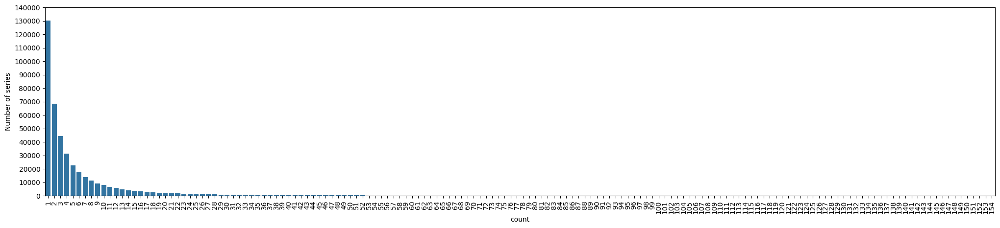

In [ ]:
plt.figure(figsize = (25,5))
sns.barplot(y = ids_per_count['Number of series'], x = ids_per_count.index)
plt.xticks(rotation=90)
plt.yticks(np.arange(0,150000,10000))
plt.show()

In [ ]:
# Removing short series
ids_to_remove = counts_per_id[counts_per_id['count'] < 155].index.tolist()


In [ ]:
sales_cleaned = sales.loc[~sales['unique_id'].isin(ids_to_remove)]

In [ ]:
# Summary
sales_cleaned.iloc[:,1:].describe(include='all')

,date_block_num,shop_id,item_id,item_price,item_cnt_day,unique_id
count,144977.0000,144977.0000,144977.0000,144977.0000,144977.0000,144977.0000
unique,34.0000,51.0000,153.0000,NaN,NaN,575.0000
top,11.0000,31.0000,20949.0000,NaN,NaN,146521.0000
freq,6817.0000,22526.0000,31283.0000,NaN,NaN,867.0000
mean,NaN,NaN,NaN,1015.7553,2.6686,NaN
std,NaN,NaN,NaN,2257.4432,8.1437,NaN
min,NaN,NaN,NaN,0.5000,-16.0000,NaN
25%,NaN,NaN,NaN,149.5000,1.0000,NaN
50%,NaN,NaN,NaN,599.5000,1.0000,NaN
75%,NaN,NaN,NaN,1049.0000,2.0000,NaN


In [ ]:
len(sales_cleaned['unique_id'].unique())

575

Removing short series reduced store count to 51 and item count to 153. This means many items were not sold regularly.

#### Removing series with multiple missing dates

In [ ]:
# Checking selling days per shop
sales_cleaned['dayofweek'] = sales_cleaned['date'].dt.day_of_week
days_per_shop = sales_cleaned.pivot_table(index = 'shop_id', values = 'dayofweek', aggfunc= lambda group: len(group.unique()))
days_per_shop = days_per_shop.rename(columns = {'dayofweek':'#_days_sold'})
days_per_shop[days_per_shop.index.isin(sales_cleaned['shop_id'].unique())]['#_days_sold'].unique()

array([7], dtype=int64)

Each shop sells goods throughout a whole week. There are no day-sensitive shops.

In [ ]:
# Checking selling days per item

In [ ]:
days_per_item = sales_cleaned.pivot_table(index = 'item_id', values = 'dayofweek', aggfunc= lambda group: len(group.unique()))
days_per_item = days_per_item.rename(columns = {'dayofweek':'#_days_sold'})
days_per_item[days_per_item.index.isin(sales_cleaned['item_id'].unique())]['#_days_sold'].unique()

array([7, 6], dtype=int64)

In [ ]:
days_per_item[days_per_item['#_days_sold']==6]

,#_days_sold
item_id,
13753,6


In [ ]:
sales_cleaned.loc[sales_cleaned['item_id']==13753,'dayofweek'].unique()

array([3, 2, 0, 4, 1, 5])

In [ ]:
sales_cleaned.loc[sales_cleaned['item_id']==13753,'unique_id'].unique()

array([11326], dtype=object)

All items are being sold throughput the whole week, except for item 13753, which series do not contain Sunday data. This id refers to the delivery of goods, which means lack of Sunday deliveries is not related to data issue, but to item specifics.

In [ ]:
# Checking how many series have less than 15% of missing values

It was shown that all shops and almost all items are not day-specific. Therefore  series with more than 15% of missing values will be filtered out. Those series represent rarely sold items within specific shops, and for such pairs monthly or quarterly forecasting would be more appropriate, depending on an item.

In [ ]:
dates_ranges = sales_cleaned[['unique_id','date']].groupby('unique_id').agg(Start = ('date',np.min), End = ('date',np.max)).reset_index()
dates_ranges['Length'] = dates_ranges['End'].values  - dates_ranges['Start'].values +1
dates_ranges['Length'] = dates_ranges['Length'].dt.days
dates_ranges['Ranges'] = dates_ranges.apply(lambda x: pd.date_range(start=x['Start'], end=x['End'], freq="D"), axis =1)
dates_ranges['Missing dates'] = dates_ranges.apply(lambda x: x['Ranges'][~x['Ranges'].isin(sales_cleaned.loc[sales_cleaned['unique_id']==x['unique_id'],'date'])], axis = 1)
dates_ranges['%_missing'] = dates_ranges.apply(lambda x: len(x['Missing dates'])/x['Length'], axis = 1)
dates_ranges = dates_ranges.sort_values(by='%_missing',ascending=False)

In [ ]:
dates_ranges['%_missing'].describe()

count   575.0000
mean      0.6908
std       0.1814
min       0.0082
25%       0.6613
50%       0.7532
75%       0.8038
max       0.8503
Name: %_missing, dtype: float64

In [ ]:
(dates_ranges['%_missing'] <=0.15).sum()

22

Majority of the series have more than 15% of values missing. Those will be removed.

In [ ]:
# Removal
sales_cleaned2 = sales_cleaned.loc[sales_cleaned['unique_id'].isin(dates_ranges.loc[(dates_ranges['%_missing'] <=0.15),'unique_id'].values),:]

In [ ]:
# Checking % of missing values in the remaining dataset

dates_ranges.loc[dates_ranges['unique_id'].isin(sales_cleaned2['unique_id'].unique()),['unique_id','%_missing']]

,unique_id,%_missing
472,352723,0.1498
385,278158,0.1358
109,112592,0.1315
11,26329,0.1261
484,353813,0.1238
371,253687,0.1197
470,352721,0.1039
336,200573,0.1033
348,222650,0.1018
567,417360,0.1016


#### Numerical features exploration

In [ ]:
sales_cleaned2[['item_price','item_cnt_day']].describe()

,item_price,item_cnt_day
count,15793.0000,15793.0000
mean,92.6336,8.0070
std,244.0281,10.5983
min,4.0000,-16.0000
25%,5.0000,2.0000
50%,5.0000,5.0000
75%,5.0000,10.0000
max,1000.0000,501.0000


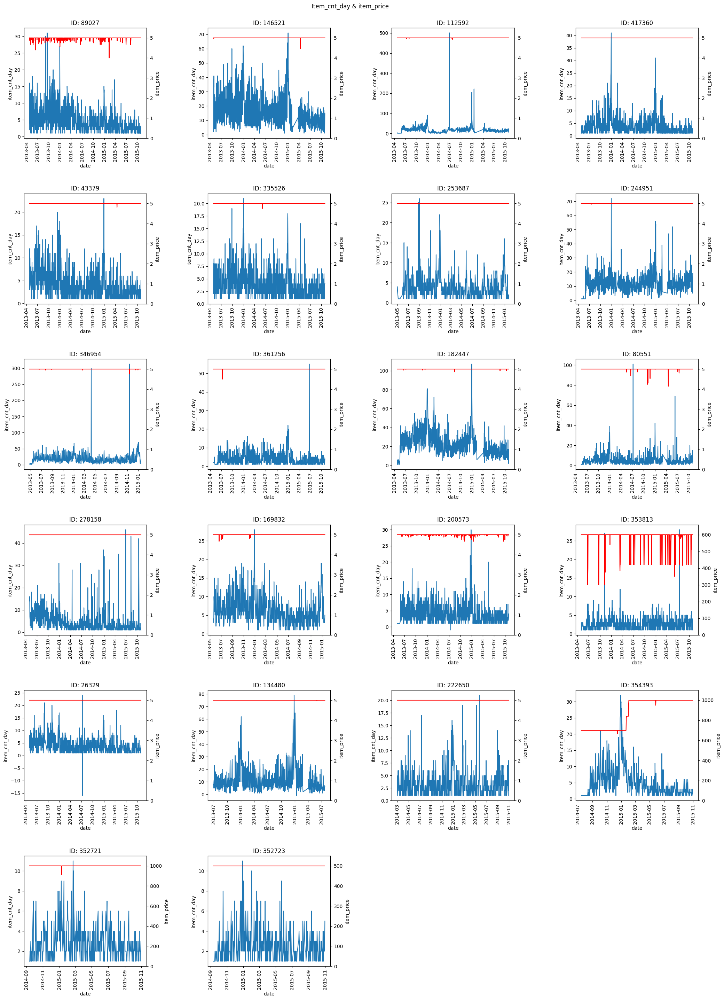

In [ ]:
# Plotting item_cnt_day

fig, axs = plt.subplots(6,4, figsize = (25, 35))
fig.suptitle('Item_cnt_day & item_price', y= 0.9)
fig.subplots_adjust(hspace=0.5, wspace = 0.5)
for id, ax in zip(sales_cleaned2['unique_id'].unique(), axs.ravel()):
    sns.lineplot(sales_cleaned2[sales_cleaned2['unique_id']==id], y = 'item_cnt_day', x = 'date', ax = ax)
    ax2 = ax.twinx()
    sns.lineplot(sales_cleaned2[sales_cleaned2['unique_id']==id], y = 'item_price', x = 'date', color = 'red', ax = ax2)
    ax.set_title(f'ID: {id}')
    ax.set_xticklabels(ax.get_xticklabels(), rotation = 90)
    ax2.set_ylim(bottom=0, top = 1.1*np.max(sales_cleaned2.loc[sales_cleaned2['unique_id']==id,'item_price']))
fig.delaxes(axs[5,2])
fig.delaxes(axs[5,3])
plt.show()



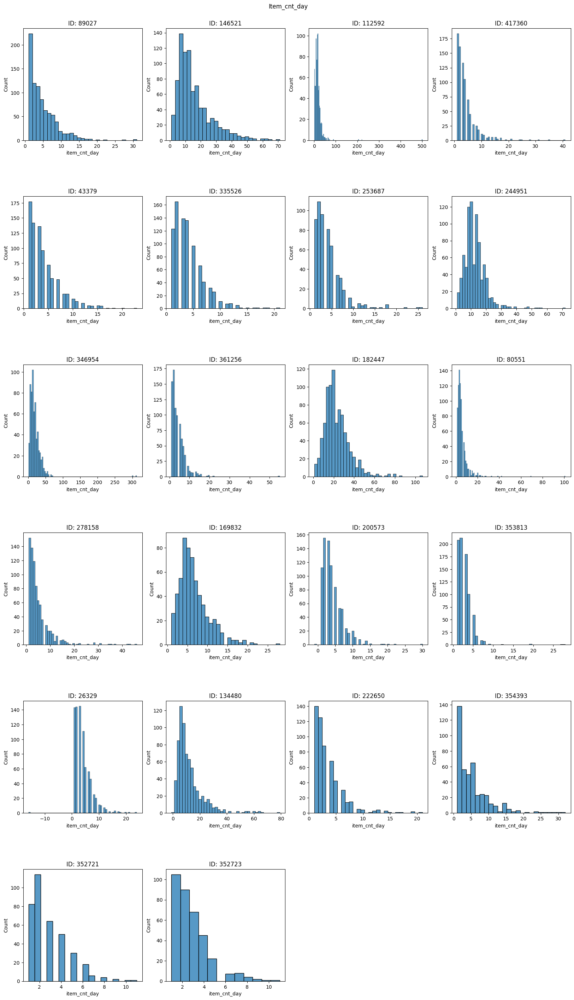

In [ ]:
# Plotting item_cnt_day distribution

fig, axs = plt.subplots(6,4, figsize = (20, 35))
fig.suptitle('Item_cnt_day', y= 0.9)
fig.subplots_adjust(hspace=0.5)
for id, ax in zip(sales_cleaned2['unique_id'].unique(), axs.ravel()):
    sns.histplot(sales_cleaned2.loc[sales_cleaned2['unique_id']==id,'item_cnt_day'], ax = ax)
    ax.set_title(f'ID: {id}')
fig.delaxes(axs[5,2])
fig.delaxes(axs[5,3])
plt.show()



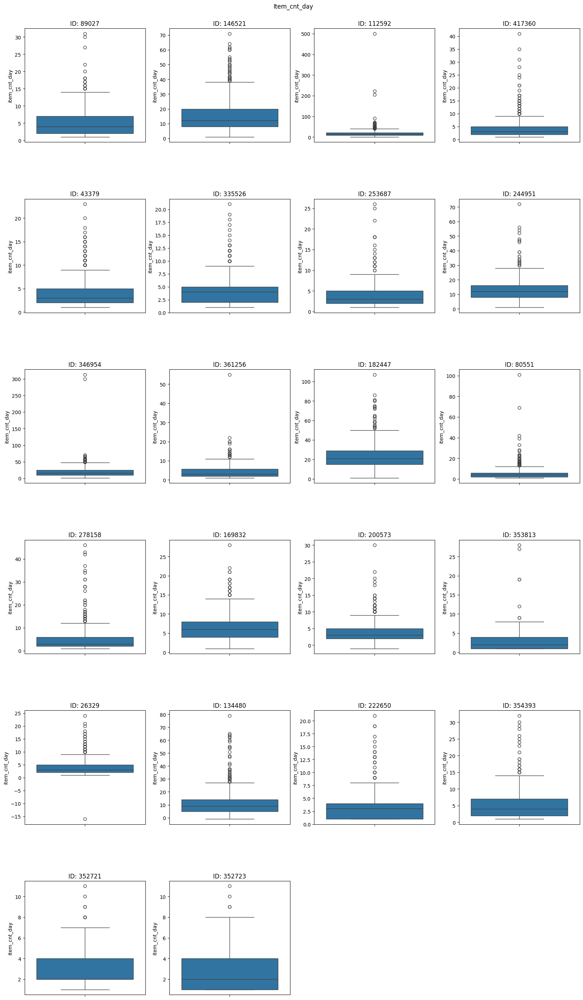

In [ ]:
# Plotting item_cnt_day boxplots

fig, axs = plt.subplots(6,4, figsize = (20, 35))
fig.suptitle('Item_cnt_day', y= 0.9)
fig.subplots_adjust(hspace=0.5)
for id, ax in zip(sales_cleaned2['unique_id'].unique(), axs.ravel()):
    sns.boxplot(sales_cleaned2.loc[sales_cleaned2['unique_id']==id,'item_cnt_day'], ax = ax)
    ax.set_title(f'ID: {id}')
fig.delaxes(axs[5,2])
fig.delaxes(axs[5,3])
plt.show()



In [ ]:
sales_cleaned2[sales_cleaned2['item_cnt_day']<0]

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,unique_id,dayofweek
1804857,2014-07-14,18,35,20949,5.0000,-1.0000,200573,0
1835454,2014-07-10,18,14,20949,5.0000,-16.0000,26329,3
2323751,2015-01-12,24,27,20949,5.0000,-1.0000,134480,0


From above charts, it is visible all count variables have right-skewed distribution, and therefore boxplots indicated outliers. Looking at lineplots though, it is visible some series have super extreme values, such as IDs 112592 and 356954. In majority of cases, extreme values in item_cnt_day variable are not correlated with changes in item_price, except for series 353813.

In three series, returns of goods can be observed (negative values).

##### Handling negative values - item_cnt_day

In [ ]:
sales_cleaned2[sales_cleaned2['unique_id']==26329].sort_values(by='date')[sales_cleaned2['date'].between('2014-07-01','2014-07-31')].head(20)

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,unique_id,dayofweek
1835442,2014-07-01,18,14,20949,5.0000,4.0000,26329,1
1835443,2014-07-02,18,14,20949,5.0000,1.0000,26329,2
1835444,2014-07-03,18,14,20949,5.0000,2.0000,26329,3
1835460,2014-07-04,18,14,20949,5.0000,1.0000,26329,4
1835459,2014-07-05,18,14,20949,5.0000,8.0000,26329,5
1835458,2014-07-06,18,14,20949,5.0000,3.0000,26329,6
1835457,2014-07-07,18,14,20949,5.0000,3.0000,26329,0
1835456,2014-07-08,18,14,20949,5.0000,24.0000,26329,1
1835455,2014-07-09,18,14,20949,5.0000,4.0000,26329,2
1835454,2014-07-10,18,14,20949,5.0000,-16.0000,26329,3


In [ ]:
sales_cleaned2[sales_cleaned2['unique_id']==200573].sort_values(by='date')[sales_cleaned2['date'].between('2014-07-01','2014-07-31')].head(20)

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,unique_id,dayofweek
1804888,2014-07-02,18,35,20949,5.0000,1.0000,200573,2
1804869,2014-07-03,18,35,20949,5.0000,2.0000,200573,3
1804867,2014-07-04,18,35,20949,5.0000,4.0000,200573,4
1804866,2014-07-05,18,35,20949,5.0000,3.0000,200573,5
1804865,2014-07-06,18,35,20949,5.0000,4.0000,200573,6
1804864,2014-07-07,18,35,20949,5.0000,4.0000,200573,0
1804863,2014-07-08,18,35,20949,5.0000,3.0000,200573,1
1804862,2014-07-09,18,35,20949,5.0000,1.0000,200573,2
1804861,2014-07-10,18,35,20949,5.0000,4.0000,200573,3
1804860,2014-07-11,18,35,20949,5.0000,4.0000,200573,4


In [ ]:
sales_cleaned2[sales_cleaned2['unique_id']==134480].sort_values(by='date')[sales_cleaned2['date'].between('2015-01-01','2015-01-31')].head(20)

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,unique_id,dayofweek
2323742,2015-01-01,24,27,20949,5.0000,31.0000,134480,3
2323743,2015-01-02,24,27,20949,5.0000,65.0000,134480,4
2323744,2015-01-03,24,27,20949,5.0000,63.0000,134480,5
2323745,2015-01-04,24,27,20949,5.0000,51.0000,134480,6
2323746,2015-01-05,24,27,20949,5.0000,33.0000,134480,0
2323747,2015-01-06,24,27,20949,5.0000,26.0000,134480,1
2323748,2015-01-07,24,27,20949,5.0000,21.0000,134480,2
2323750,2015-01-08,24,27,20949,5.0000,25.0000,134480,3
2323759,2015-01-09,24,27,20949,5.0000,18.0000,134480,4
2323751,2015-01-12,24,27,20949,5.0000,-1.0000,134480,0


Looking at dataframes of series with returns, it is visible that before each return, there is a day with higher than usual number of items purchased. This may mean some volume from those days were returned later. Is is especially visible in the dataframe where firstly 24 items were purchased on 2014-07-08 and then 16 were returned of 2014-07-10.  As  returns influence the actual number of items sold, but are unexpected are are not the subject of forecasting, their values will be replaced by zeros (as no items were purchased on those days), but number of returned items will be subtracted from preceding days with higher number of items sold.

In [ ]:
sales_cleaned2 = sales_cleaned2.sort_values(by='date')
sales_cleaned2 = sales_cleaned2.reset_index(drop=True)

In [ ]:
# Cleaning  returns
sales_cleaned2 = eda.returns(sales_cleaned2)

##### Outliers - item_cnt_day

Number of outliers will be estimated using adjusted z-scores for skewed distributions.

In [ ]:
# Adding Russian holidays

hol = holidays.RU(years = [2013, 2014, 2015], language = 'en_US')

# Adding day before and day after each Holiday for possible impact

holiday = set.union(set([x+timedelta(days=1) for x in hol.keys()]),set([x-timedelta(days=1) for x in hol.keys()]), set(hol.keys()))

In [ ]:
sales_cleaned2['Holiday'] = sales_cleaned2['date'].isin(holiday).astype(int)

In [ ]:
outliers_zscore = sales_cleaned2.copy()
zscores = outliers_zscore.groupby('unique_id').apply(lambda group: eda.modif_z_score(group['item_cnt_day'])).reset_index()
zscores=zscores.rename(columns={'item_cnt_day':'Z-score'})

In [ ]:
outliers_zscore = outliers_zscore.join(zscores[['level_1','Z-score']].set_index('level_1'))

In [ ]:
outliers_zscore['Outlier'] = (outliers_zscore['Z-score']>3.5)&(outliers_zscore['Holiday']<1)
outliers_zscore['Outlier'] = outliers_zscore['Outlier'].astype(int)

In [ ]:
# Outlier % per series
outliers_share = outliers_zscore[['unique_id','Outlier']].groupby('unique_id').apply(lambda group: group['Outlier'].sum()/len(group)).\
    reset_index().rename(columns = {0:'Outliers share'}).\
        sort_values(by = 'Outliers share', ascending=False)

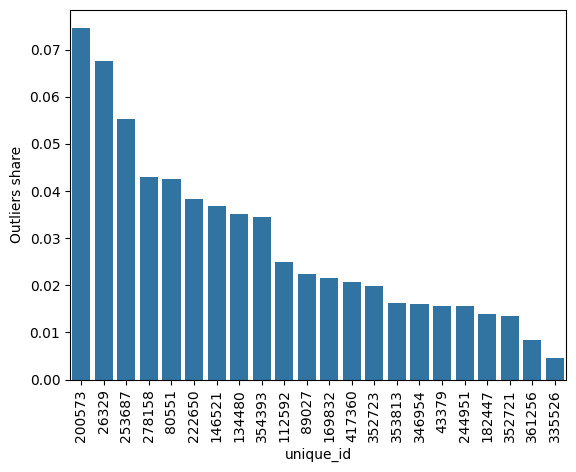

In [ ]:
sns.barplot(outliers_share, y = 'Outliers share', x = 'unique_id', order = outliers_share['unique_id'])
#plt.axhline(0.03, color='red')
plt.xticks(rotation=90)
plt.show()

In [ ]:
outlier_ids = outliers_share['unique_id'].values

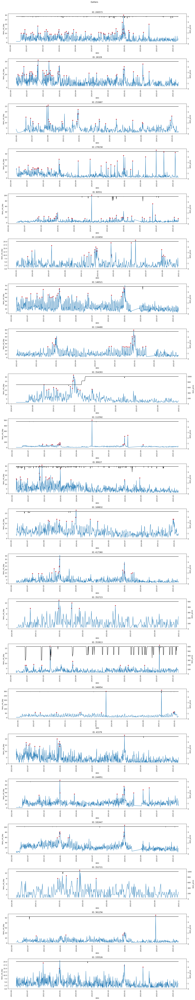

In [ ]:
# Plotting item_cnt_day and outliers

fig, axs = plt.subplots(22,1, figsize = (20, 22*5))
fig.suptitle('Outliers', y= 0.89)
fig.subplots_adjust(hspace=0.5, wspace = 0.5)
for id, ax in zip(outlier_ids, axs.ravel()):

    df = outliers_zscore.loc[outliers_zscore['unique_id']==id,:]
    sns.lineplot(df, y = 'item_cnt_day', x = 'date', ax = ax)
    sns.scatterplot(df[df['Outlier']==1], y = 'item_cnt_day', x = 'date', color = 'red', ax = ax)
    ax.set_title(f'ID: {id}')

    ax.set_xticklabels(ax.get_xticklabels(), rotation = 90)
    ax2 = ax.twinx()
    sns.lineplot(df, y = 'item_price', x = 'date', color = 'black', ax = ax2)
    ax2.set_ylim(bottom=0, top = 1.1*np.max(df['item_price']))

plt.show()



In [ ]:
# Checking how many series refer to the same item

outliers_zscore[outliers_zscore['unique_id'].isin(outlier_ids)].groupby('item_id').\
    apply(lambda x: x['unique_id'].drop_duplicates()).reset_index(level=0).\
        merge(outliers_share[['unique_id','Outliers share']], on='unique_id').\
        sort_values(by=['item_id','Outliers share'], ascending=False)

,item_id,unique_id,Outliers share
17,20949,200573,0.0747
16,20949,26329,0.0677
14,20949,253687,0.0554
15,20949,278158,0.0430
18,20949,80551,0.0425
21,20949,222650,0.0383
11,20949,146521,0.0369
20,20949,134480,0.0352
6,20949,112592,0.0250
5,20949,89027,0.0224


**Outlier conclusions**

*   For series conncected with items 13099, 13097 and 7967, peaks are the result of seasonal fluctuations and are not actual outliers.
*   For series 353813, extreme points are the result of both seasonal and price fluctuations, which may mean some price deals were run for this product
*   For item 20949, there are both peaks related to seasonal patterns, but there are also some extreme values occuring up to several times within each series. Those extreme values are not related to price decrease, but given they are present in all series of item 20949, cannot be considered as data errors. Those will be left in the dataset but marked as potential promotions.

In [ ]:
threshold = np.repeat(2.8,22)

In [ ]:
threshold[0] = 3
threshold[3] = 3
threshold[5:8] = 3.3
threshold[4] = 13
threshold[10] = 3
threshold[11] = 5
threshold[12] = 8
threshold[15] = 4
threshold[16] = 6
threshold[17] = 1.1
threshold[20] = 3.5
threshold[21] = 1.5

In [ ]:
sales_cleaned2['Outlier'] = (outliers_zscore['Z-score']>3.5)&(outliers_zscore['Holiday']<1)
sales_cleaned2['Outlier'] = sales_cleaned2['Outlier'].astype(int)

In [ ]:
sales_cleaned2 = eda.extreme(sales_cleaned2, threshold, outlier_ids)

In [ ]:
sales_cleaned2 = sales_cleaned2.drop('Outlier', axis = 1)

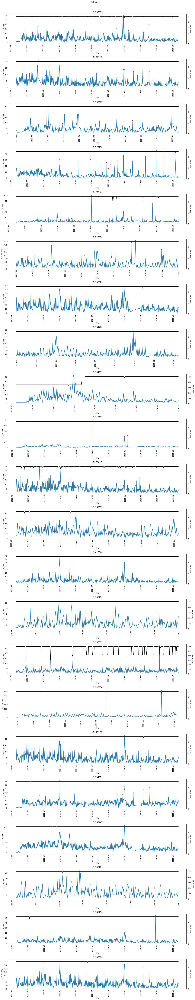

In [ ]:
# Plotting item_cnt_day and outliers

fig, axs = plt.subplots(22,1, figsize = (20, 22*5))
fig.suptitle('Outliers', y= 0.89)
fig.subplots_adjust(hspace=0.5, wspace = 0.5)
for id, ax in zip(outlier_ids, axs.ravel()):

    df = sales_cleaned2.loc[sales_cleaned2['unique_id']==id,:]
    sns.lineplot(df, y = 'item_cnt_day', x = 'date', ax = ax)
    sns.scatterplot(df[df['Promo']==1], y = 'item_cnt_day', x = 'date', color = 'red', ax = ax)
    ax.set_title(f'ID: {id}')
    ax.set_xticklabels(ax.get_xticklabels(), rotation = 90)
    ax2 = ax.twinx()
    sns.lineplot(df, y = 'item_price', x = 'date', color = 'black', ax = ax2)
    ax2.set_ylim(bottom=0, top = 1.1*np.max(df['item_price']))

plt.show()



##### Item_price

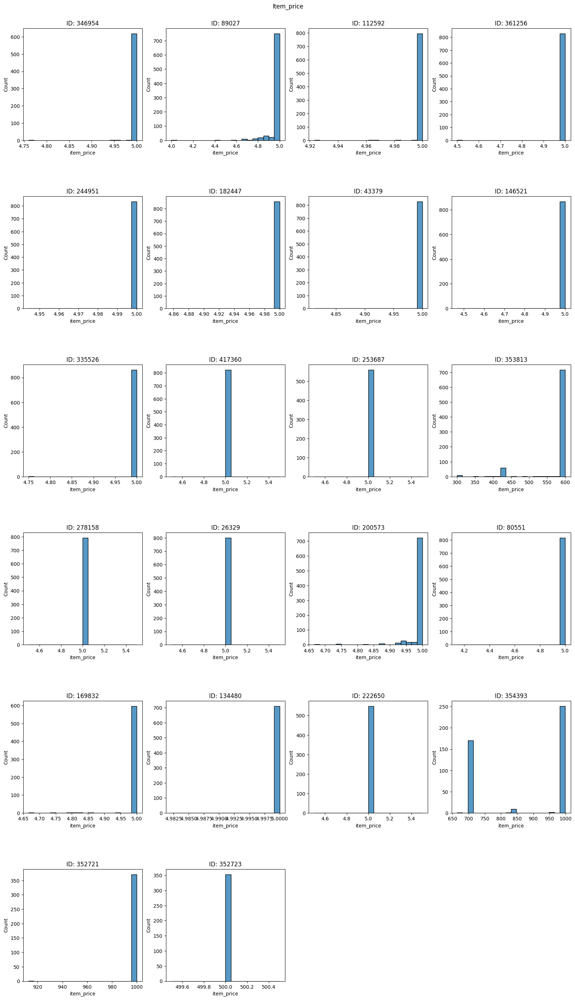

In [ ]:
# Plotting item_price distribution

fig, axs = plt.subplots(6,4, figsize = (20, 35))
fig.suptitle('Item_price', y= 0.9)
fig.subplots_adjust(hspace=0.5)
for id, ax in zip(sales_cleaned2['unique_id'].unique(), axs.ravel()):
    sns.histplot(sales_cleaned2.loc[sales_cleaned2['unique_id']==id,'item_price'], bins = 20, ax = ax)
    ax.set_title(f'ID: {id}')
fig.delaxes(axs[5,2])
fig.delaxes(axs[5,3])
plt.show()



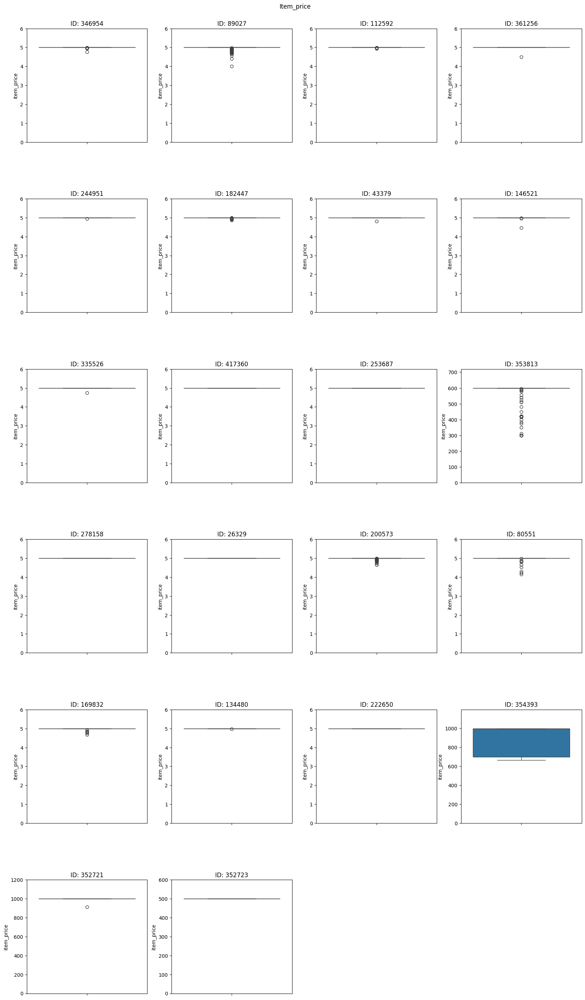

In [ ]:
# Plotting item_price boxplots

fig, axs = plt.subplots(6,4, figsize = (20, 35))
fig.suptitle('Item_price', y= 0.9)
fig.subplots_adjust(hspace=0.5)
for id, ax in zip(sales_cleaned2['unique_id'].unique(), axs.ravel()):
    sns.boxplot(sales_cleaned2.loc[sales_cleaned2['unique_id']==id,'item_price'], ax = ax)
    ax.set_title(f'ID: {id}')
    ax.set_ylim(0,np.max(sales_cleaned2.loc[sales_cleaned2['unique_id']==id,'item_price'])*1.2)
fig.delaxes(axs[5,2])
fig.delaxes(axs[5,3])
plt.show()




Item price is in majority of series stable variable over time, with only several series with fluctuations:
*   353813, where price decrease is connected with jumps in sales with may mean some price deals
*   354393, where price increased in 2015 causing drop in sales
*   In remaining series, price changes are not drastic and rather standard effect on the market

##### Correlations

In [ ]:
correlations = sales_cleaned2.groupby('unique_id').corr(method = 'spearman', numeric_only=True).reset_index(level=0)

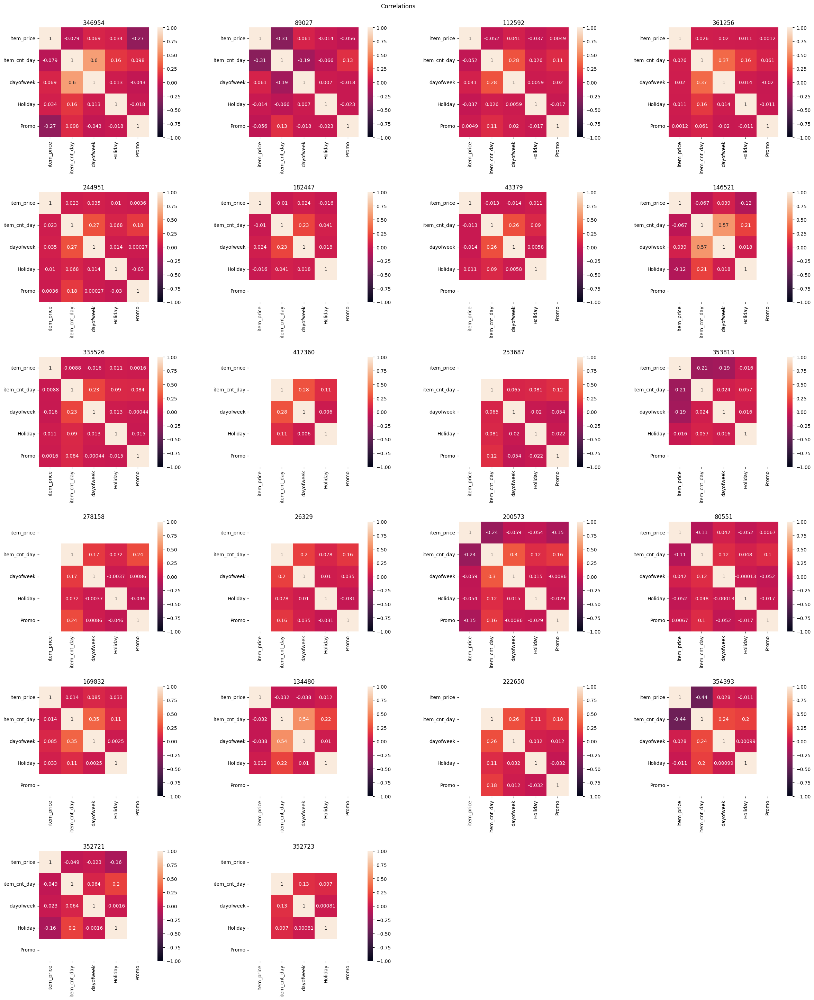

In [ ]:
fig, axs = plt.subplots(6,4, figsize = (30, 35))
fig.suptitle('Correlations', y= 0.9)
fig.subplots_adjust(hspace=0.5)
for id, ax in zip(sales_cleaned2['unique_id'].unique(), axs.ravel()):
    ax.set_title(f'{id}')
    visuals.draw_heatmap(correlations.loc[correlations['unique_id']==id,:], ax = ax)
fig.delaxes(axs[5,2])
fig.delaxes(axs[5,3])
plt.show()

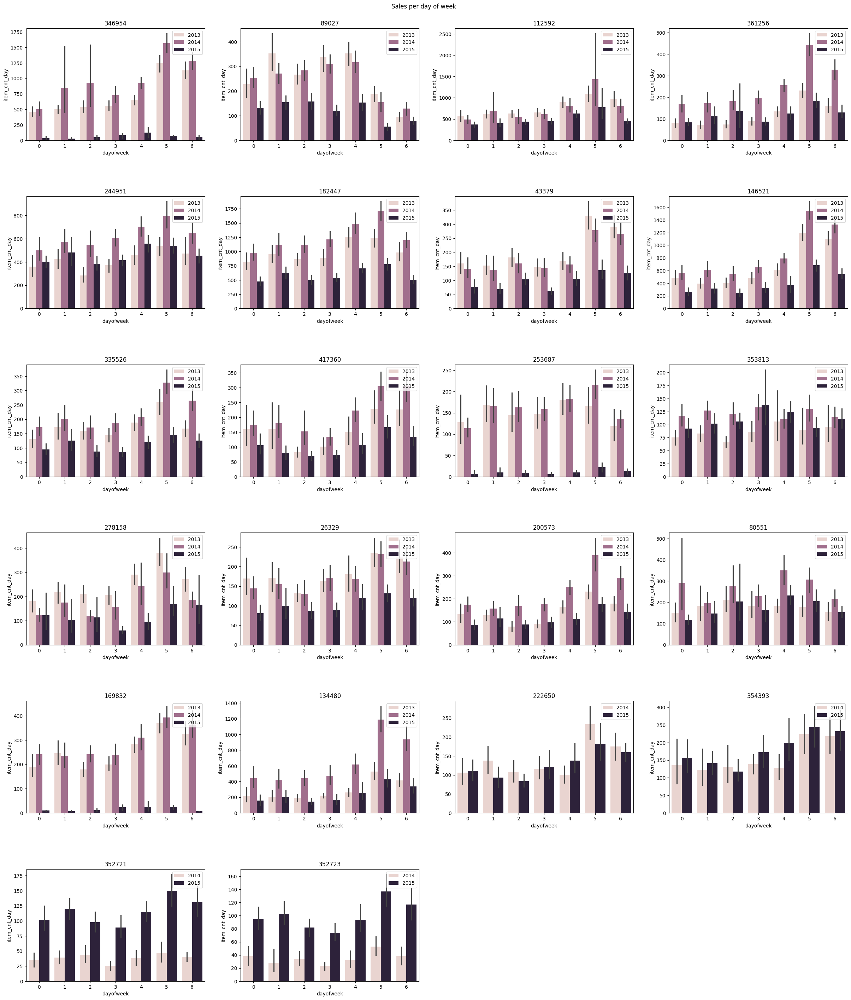

In [ ]:
# Sales per day
fig, axs = plt.subplots(6,4, figsize = (30, 35))
fig.suptitle('Sales per day of week', y= 0.9)
fig.subplots_adjust(hspace=0.5)
for id, ax in zip(sales_cleaned2['unique_id'].unique(), axs.ravel()):
    ax.set_title(f'{id}')
    sns.barplot(sales_cleaned2.loc[sales_cleaned2['unique_id']==id,:],
                y = 'item_cnt_day', x = 'dayofweek', estimator = 'sum',
                hue = sales_cleaned2.loc[sales_cleaned2['unique_id']==id,'date'].dt.year,
                ax = ax)
    ax.legend(loc = 'upper right')
fig.delaxes(axs[5,2])
fig.delaxes(axs[5,3])
plt.show()

**Correlation conclusions**

From above heatmap charts, several thing can be noticed:
*   Overall correlations between variables are low, only with several cases exceeding 0.5
*   Item_price is correlated with item_cnt_day mostly in series 354393, 89027, 200573 and 353813. Correlation is negative, which results from previous sections regarding price-sales relation. In the rest of series, correlation is either minimal or unable to estimate due to low variability of price - in the latter case, price is not sensitive to changes in sales looking at previous charts.
*   Item_cnt_day besides price is also correlated with day of week, with the coefficient exceeding 0.5 for some series. It is visible in the majority of series that sales peak during weekend (positive correlation), drop during weekend (series 89027, negative correlation) or are quite stable within the whole week (minimal correlation).


## Inputting missing values

In [ ]:
sales_w_gaps = fill_gaps(sales_cleaned2, freq='D', start = 'per_serie', end = 'per_serie', time_col='date')

In [ ]:
sales_w_gaps['Missing'] = sales_w_gaps['item_cnt_day'].isna().astype(int)

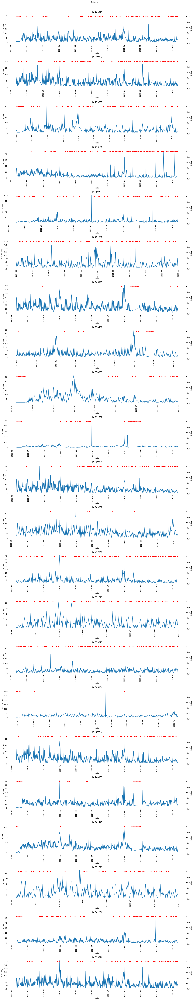

In [ ]:
# Plotting gaps

fig, axs = plt.subplots(22,1, figsize = (20, 22*5))
fig.suptitle('Outliers', y= 0.89)
fig.subplots_adjust(hspace=0.5, wspace = 0.5)
for id, ax in zip(outlier_ids, axs.ravel()):

    df = sales_w_gaps.loc[sales_w_gaps['unique_id']==id,:]
    sns.lineplot(df, y = 'item_cnt_day', x = 'date', ax = ax)
    ax.set_title(f'ID: {id}')
    ax.set_xticklabels(ax.get_xticklabels(), rotation = 90)
    ax2 = ax.twinx()
    sns.scatterplot(df[df['Missing']==1], y = 'Missing', x = 'date', color = 'red', ax = ax2)
    ax2.set_ylim(bottom=0, top = 1.1)

plt.show()



In [ ]:
first_months = sales_w_gaps.groupby(['unique_id','date_block_num']).\
    count().reset_index().groupby('unique_id').\
        apply(lambda group: group.head(2)).reset_index(drop = True)[['unique_id','date_block_num','date']]
first_months = first_months.rename(columns={'date':'Count'})
first_months = first_months[first_months['Count']<15]
first_months

,unique_id,date_block_num,Count
2,43379,3,4
4,80551,4,11
6,89027,3,7
8,112592,3,3
9,112592,4,11
10,134480,5,2
12,146521,3,2
14,169832,4,12
16,182447,3,4
18,200573,4,5


Conclusions and next steps:

*   Many series have missing values in the first or second month. Those initial months will be dropped
*   For remaining missing values, they will be imputted using :
    *   Seasonal decomposition for item_cnt_day,
    *   Matching date-date_block_num for block numbers
    *   Mathing unique_id-hop_id-item_id for shop and item ids
    *   Previous value for price due to low variability

In [ ]:
rows_to_remove = dict(
    keys = first_months['unique_id'].unique(),
    values = [list(first_months.loc[first_months['unique_id']==id,'date_block_num']) for id in first_months['unique_id'].unique()]
)

In [ ]:
# Inputting values and removing initial months
sales_cleaned3 = eda.clean_data(sales_w_gaps, rows_to_remove,holiday)

In [ ]:
# Inputting item_cnt day
sales_cleaned3 = eda.input_target(sales_cleaned3)

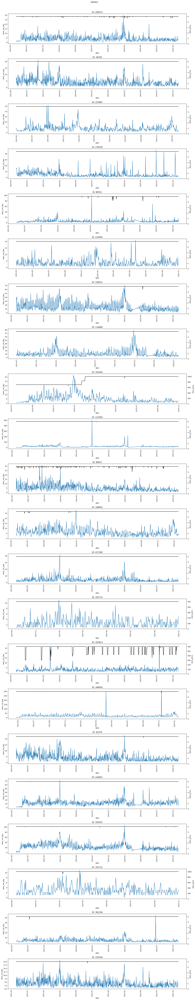

In [ ]:
# Plotting item_cnt_day and outliers

fig, axs = plt.subplots(22,1, figsize = (20, 22*5))
fig.suptitle('Outliers', y= 0.89)
fig.subplots_adjust(hspace=0.5, wspace = 0.5)
for id, ax in zip(outlier_ids, axs.ravel()):

    df = sales_cleaned3.loc[sales_cleaned3['unique_id']==id,:]
    sns.lineplot(df, y = 'item_cnt_day', x = 'date', ax = ax)
    ax.set_title(f'ID: {id}')
    ax.set_xticklabels(ax.get_xticklabels(), rotation = 90)
    ax2 = ax.twinx()
    sns.lineplot(df, y = 'item_price', x = 'date', color = 'black', ax = ax2)
    ax2.set_ylim(bottom=0, top = 1.1*np.max(df['item_price']))

plt.show()



## ACF/PACF plots

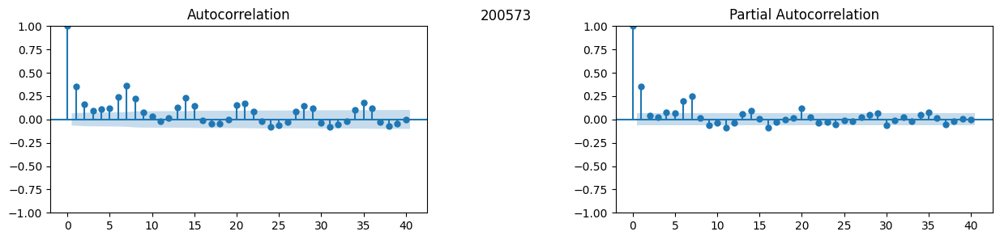

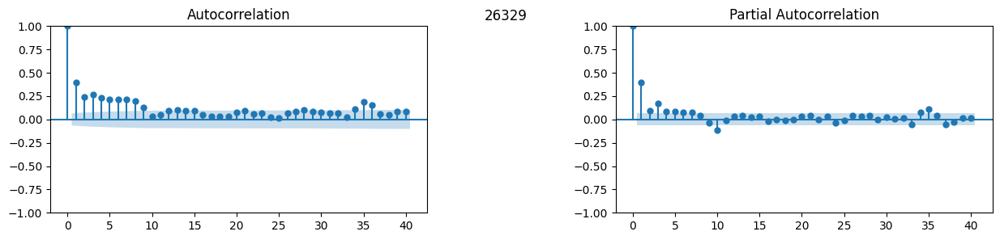

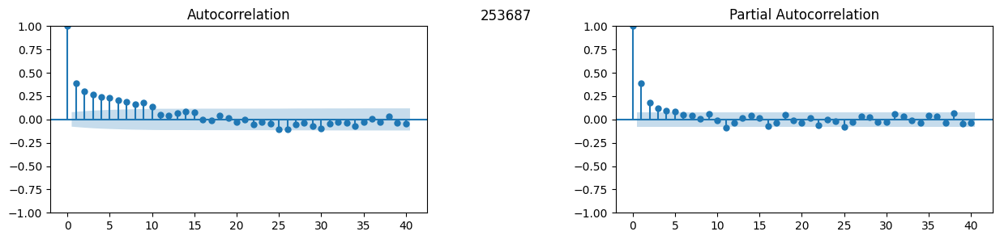

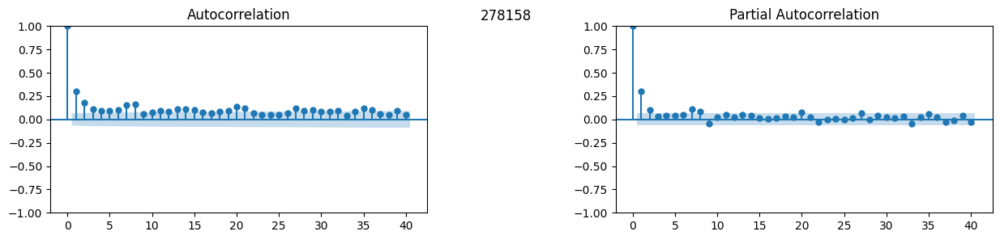

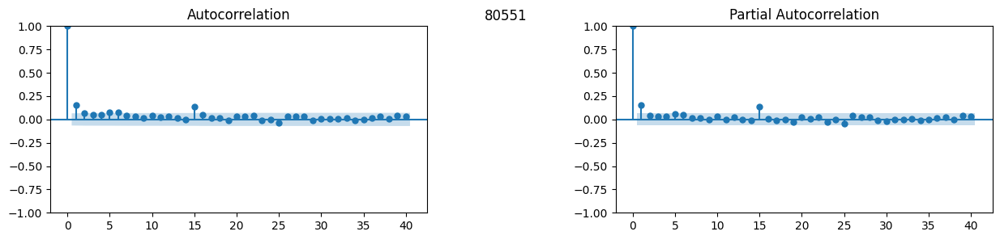

...

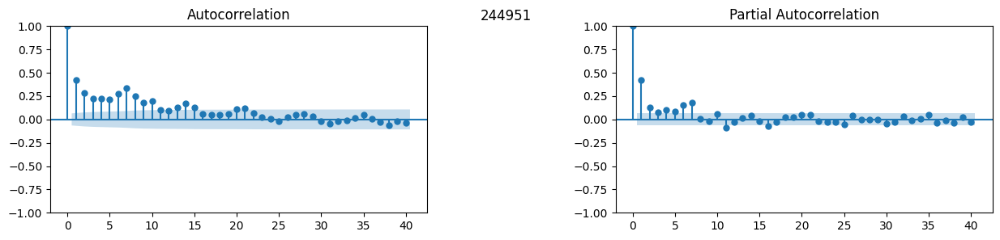

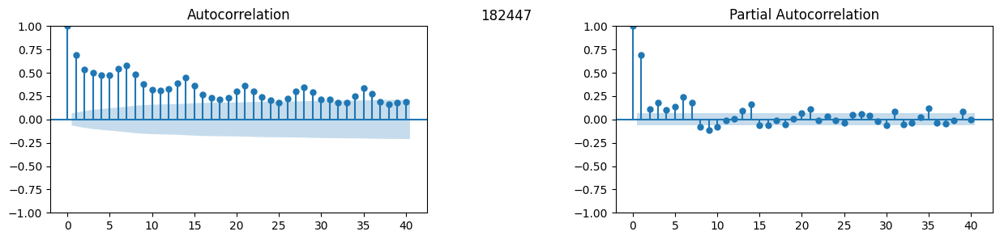

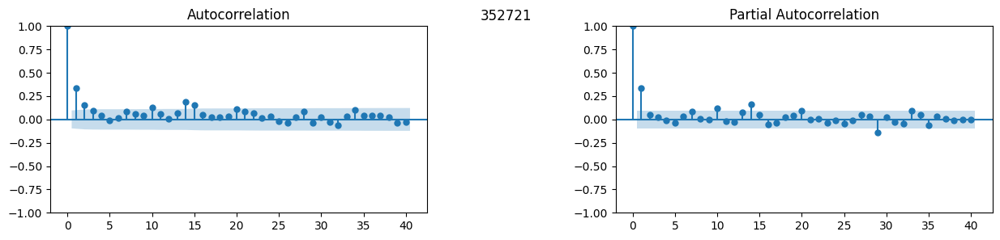

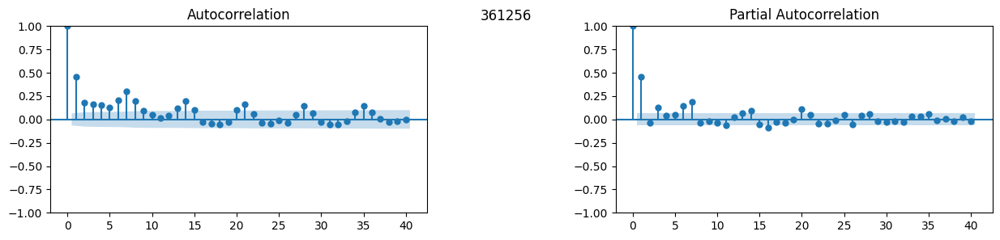

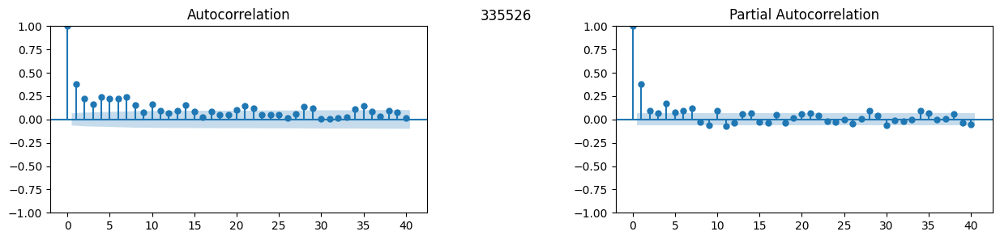

In [ ]:
# Plotting acf and pacf


for i, id in enumerate(outlier_ids):

    fig, axs = plt.subplots(1,2, figsize = (15, 3))
    fig.suptitle(f'{id}', y= 0.95)
    fig.subplots_adjust(hspace=0.5, wspace = 0.5)
    df = sales_cleaned3.loc[sales_cleaned3['unique_id']==id,:]
    plot_acf(df['item_cnt_day'], lags=40, ax = axs[0])
    ax.set_xticklabels(ax.get_xticklabels(), rotation = 90)
    plot_pacf(df['item_cnt_day'], lags=40, ax = axs[1])

plt.show()



As it was noticed previously, weekly seasonality is observed in the majority of series.

## Generating features

Several more features will be added to dataframe for forecasting horizon of 31 days (1 month ahead):
*   Datetime - year, month
*   Cyclical features
*   Lag 35 to capture seasonal fluctuations
*   Rolling mean, std from past 35 days

In [ ]:
# Datetime, cyclical

sales_cleaned3['year'] = sales_cleaned3['date'].dt.year
sales_cleaned3['month'] = sales_cleaned3['date'].dt.month
sales_cleaned3 = eda.cyclic_features(sales_cleaned3, 'dayofweek', sales_cleaned3['dayofweek'], 7)

In [ ]:
sales_cleaned3.shape

(17362, 14)

In [ ]:
# Lag

sales_cleaned3['Lag35'] = sales_cleaned3.groupby('unique_id').apply(lambda group: group['item_cnt_day'].shift(35)).values
sales_cleaned3['Rollingmean35'] = sales_cleaned3.groupby('unique_id').apply(lambda group: group['item_cnt_day'].shift(1).rolling(35).mean()).values
sales_cleaned3['Rollingstd35'] = sales_cleaned3.groupby('unique_id').apply(lambda group: group['item_cnt_day'].shift(1).rolling(35).std()).values


In [ ]:
sales_cleaned3 = sales_cleaned3.dropna()

Features referring to item and shop will be dropped as they are matched to unique_id.

In [ ]:
sales_cleaned3 = sales_cleaned3.drop(['item_id','shop_id'], axis = 1)

## Train-test-validation split

In [ ]:
sales_cleaned3 = sales_cleaned3.rename(columns = {'date':'ds',
                                                  'item_cnt_day':'y'})

In [ ]:
train = sales_cleaned3.groupby('unique_id').apply(lambda group: group.iloc[:-62,:]).reset_index(drop=True)
test = sales_cleaned3.groupby('unique_id').apply(lambda group: group.iloc[-62:-31,:]).reset_index(drop=True)
val = sales_cleaned3.groupby('unique_id').tail(31)

In [ ]:
train_test = sales_cleaned3.groupby('unique_id').apply(lambda group: group.iloc[:-31,:]).reset_index(drop=True)

In [ ]:
# True values
true = sales_cleaned3.groupby('unique_id').apply(lambda group: group.iloc[-62:-31,:]).reset_index(drop=True)[['ds','unique_id','y']]
true = true.set_index('ds')

# True values - val

true_val = sales_cleaned3.groupby('unique_id').tail(31)[['ds','unique_id','y']]
true_val = true_val.set_index('ds')

In [ ]:
# Creating features lists

static = sales_cleaned3[['unique_id']].drop_duplicates().reset_index(drop = True)
static = pd.concat([static,pd.DataFrame(OneHotEncoder(sparse_output=False).fit_transform(static), columns = ['id_'+str(n) for n in static.values])], axis = 1)

In [ ]:
future = sales_cleaned3.columns.difference(['unique_id','y','ds','item_price']).tolist()
hist = ['item_price']

# **2. Multivariate forecasting**

For forecasting, 3 models will be trained and evaluated on test set for 1 month time period (31 days):
*   MLP (NBEATS)
*   RNN (LSTM)
*   Transformer (TFT)

### **Baseline simple model - Seasonal Naive**

In [ ]:
sf = StatsForecast(
    models=[SeasonalNaive(season_length=7)],
    freq='D',
    n_jobs=-1,
)

naive = sf.forecast(df = train,
                    h=31,
                    X_df = test[test.columns.difference(['y'])] )

In [ ]:
naive_scores = pd.DataFrame()
for id in true['unique_id'].unique():

            naive_scores = pd.concat([naive_scores, pd.DataFrame({
                'NAIVE': mean_absolute_percentage_error(true[true['unique_id']==id]['y'],np.ceil(naive[naive['unique_id']==id].iloc[:,-1]))
                }, index =[id])])
naive_scores = pd.concat([naive_scores,pd.DataFrame({
        'NAIVE': mean_absolute_percentage_error(true['y'],np.ceil(naive.iloc[:,-1])),
    }, index = ['Total MAPE'])
    ])
naive_scores

,NAIVE
26329,0.6086
43379,0.8237
80551,0.7363
89027,0.5871
112592,0.5186
134480,1.4462
146521,0.6743
169832,0.6906
182447,0.4418
200573,0.5280


Naive seasonal model has overall MAPE around 99%, with series 353813 having the lowest error (43%) and series 346954 the highest 587%.

### **Baseline models with default settings**

Firstly models without any major hyperparameter modifications will be evaluated on the test set to set up baseline scores. MAPE metric will be used to evaluate all models.

In [ ]:
settings =  {'h': 31,
            'futr_exog_list': future,
            'hist_exog_list': hist,
            'stat_exog_list': static.columns.tolist()[1:],
            'max_steps': 50
}

In [ ]:
# Neural Forecast
models1 = [
    m.NBEATSx(**settings, input_size=31),
    m.LSTM(**settings),
    m.TFT(**settings, input_size=31)
]

net1 = NeuralForecast(models = models1, freq = 'D')



Seed set to 1
Seed set to 1
Seed set to 1


In [ ]:
# Fitting NeuralForeacst models

net1.fit(df=train, val_size=31, static_df=static)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

In [ ]:
# Predictions from NeuralForecast models
fc1 = net1.predict(futr_df=test)
fc1.iloc[:,-3:] = fc1.iloc[:,-3:].map(lambda x: max(0,math.ceil(x)))

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

In [ ]:
m1 = training.get_metrics(true,fc1,id = True)
m1

,NBEATS,LSTM,TFT
26329,0.5097,0.4648,0.4674
43379,0.8140,0.6409,0.6478
80551,0.5194,0.5863,0.5514
89027,0.5785,0.8056,0.6089
112592,0.3655,0.3684,0.3867
134480,0.5338,0.8736,0.8182
146521,1.2349,0.5920,0.7461
169832,0.7036,0.6071,0.7435
182447,0.8407,0.3257,0.3627
200573,0.5699,0.3715,0.4742





In [ ]:
visuals.show_predictions(true,fc1,naive)

#### **Conclusion**

Baseline models with default settings improved MAPEs from naive models, with LSTM/TFT achieving similar scores ~62/63%, and NBEATS having the highest error above 84%.

### **Optimized models**

In this section hyperparameters will be tuned to check if the baseline scores can be improved.

In [ ]:
config_nbeats ={

                'input_size':tune.randint(31, 31*4),
                'exclude_insample_y': tune.choice([False, True]),
                'futr_exog_list': future,
                'hist_exog_list': hist,
                'stat_exog_list': static.columns.tolist()[1:],
                'n_harmonics':7,
                'n_polynomials':tune.randint(1, 5),
                'activation': tune.choice( ['ReLU','SELU','LeakyReLU','PReLU']),
                'stack_types':tune.choice([['trend','seasonality','exogenous'],['identity','seasonality','exogenous'],['identity', 'trend', 'seasonality']]),
                'mlp_units':tune.choice([
                            [[512,512], [512, 512], [512, 512]],
                            [[256,256], [256,256], [256,256]],
                            [[128,128], [128,128], [128,128]]
                            ]),
                'dropout_prob_theta': tune.uniform(0.0,0.3),
                'max_steps':tune.qrandint(50,250,10),
                'learning_rate':tune.uniform(0.001,0.01),
                'batch_size':tune.randint(11,23),
                'windows_batch_size':tune.choice([16, 32, 64]),
                'val_check_steps': tune.choice([5,10,25]),
                'scaler_type':tune.choice(['minmax','standard','robust']),
                'random_seed':tune.randint(1, 100)


}

In [ ]:
config_lstm ={
    'input_size':tune.randint(31, 31*4),
    'futr_exog_list': future,
    'hist_exog_list': hist,
    'stat_exog_list': static.columns.tolist()[1:],
    'encoder_n_layers': tune.choice([2,4,8]),
    'encoder_hidden_size': tune.choice([32, 64, 128]),
    'encoder_dropout': tune.uniform(0.0,0.2),
    'decoder_hidden_size': tune.choice([32, 64, 128]),
    'decoder_layers': tune.choice([2,4,8]),
    'max_steps':tune.qrandint(50,250,10),
    'learning_rate':tune.uniform(0.001,0.01),
    'batch_size':tune.randint(11,23),
    'windows_batch_size':tune.choice([16, 32, 64]),
    'val_check_steps': tune.choice([5,10, 25]),
    'scaler_type':tune.choice(['minmax','standard','robust']),
    'random_seed':tune.randint(1, 100)
}

In [ ]:
config_tft ={
    'input_size':tune.randint(31, 31*4),
    'futr_exog_list': future,
    'hist_exog_list': hist,
    'stat_exog_list': static.columns.tolist()[1:],
    'hidden_size': tune.choice([16, 32, 64]),
    'n_head': tune.choice([1, 2, 4, 8]),
    'attn_dropout': tune.uniform(0.0,0.3),
    'grn_activation': tune.choice(['ReLU','SELU','LeakyReLU','ELU']),
    'n_rnn_layers': tune.choice([1,2,3]),
    'dropout': tune.uniform(0.0,0.3),
    'max_steps':tune.qrandint(50,500,10),
    'learning_rate':tune.uniform(0.001,0.01),
    'batch_size':tune.randint(11,23),
    'windows_batch_size':tune.choice([16, 32, 64]),
    'val_check_steps': tune.choice([5,10, 25]),
    'scaler_type':tune.choice(['minmax','standard','robust']),
    'random_seed':tune.randint(1, 100)
}

In [ ]:
# Defining thresholds array with baseline scores
thresholds_nf = m1.iloc[-1,:]

In [ ]:
best_scores_2 = training.optim(20,train,test,true,thresholds_nf, static)

Seed set to 20


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

In [ ]:
print(f'NBEATS score: {best_scores_2["scores"][0]}\n\
LSTM score: {best_scores_2["scores"][1]}\n\
TFT score: {best_scores_2["scores"][2]}\n\
NBEATS params: {best_scores_2["params"][0]}\n\
LSTM params: {best_scores_2["params"][1]}\n\
TFT params: {best_scores_2["params"][2]}')

NBEATS score: 0.6871407903952984
LSTM score: 0.5459184887112914
TFT score: 0.5751485934876825
NBEATS params: {'input_size': 91, 'exclude_insample_y': True, 'futr_exog_list': ['Holiday', 'Lag35', 'Promo', 'Rollingmean35', 'Rollingstd35', 'date_block_num', 'dayofweek', 'dayofweek_cos', 'dayofweek_sin', 'month', 'year'], 'hist_exog_list': ['item_price'], 'stat_exog_list': ['id_[26329]', 'id_[43379]', 'id_[80551]', 'id_[89027]', 'id_[112592]', 'id_[134480]', 'id_[146521]', 'id_[169832]', 'id_[182447]', 'id_[200573]', 'id_[222650]', 'id_[244951]', 'id_[253687]', 'id_[278158]', 'id_[335526]', 'id_[346954]', 'id_[352721]', 'id_[352723]', 'id_[353813]', 'id_[354393]', 'id_[361256]', 'id_[417360]'], 'n_harmonics': 7, 'n_polynomials': 2, 'activation': 'ReLU', 'stack_types': ['identity', 'seasonality', 'exogenous'], 'mlp_units': [[512, 512], [512, 512], [512, 512]], 'dropout_prob_theta': 0.07489785553916221, 'max_steps': 180, 'learning_rate': 0.00733162444462011, 'batch_size': 21, 'windows_batch_

In [ ]:
fc2 = fc1.copy()
for i in range(3):
    if best_scores_2['params'][i] != 'default settings':
        fc2.iloc[:,-3+i]= best_scores_2['predictions'][i]

In [ ]:
m3 = training.get_metrics(true,fc2, id  = True)
m3

,NBEATS,LSTM,TFT
26329,0.4793,0.4881,0.4989
43379,0.4430,0.6091,0.4984
80551,0.6699,0.4128,0.5036
89027,0.4747,0.6089,0.8030
112592,0.6952,0.3659,0.3605
134480,0.5300,0.6554,0.7509
146521,0.5248,0.6614,0.6739
169832,0.5098,0.5874,0.5740
182447,0.4789,0.3292,0.3545
200573,0.3667,0.4414,0.4806





In [ ]:
show_predictions(true,fc2,naive)

## **Prediction on the validation set**

In [ ]:
final_params = best_scores_2['params'].copy()
for i in range(3):
    del final_params[i]['h']

In [ ]:
final_nbeats_mv = NeuralForecast(
    models = [
        m.NBEATSx(h=1,
                 **final_params[0],
                enable_progress_bar=False)
    ],
    freq = 'D'
)

final_lstm_mv = NeuralForecast(
    models = [
        m.LSTM(h=1,
              enable_progress_bar=False,
              **final_params[1])
    ],
    freq = 'D'
)

final_tft_mv = NeuralForecast(
    models = [
        m.TFT(h=1,
              enable_progress_bar=False,
             **final_params[2])
    ],
    freq = 'D'
)

final_nf_mv = [final_nbeats_mv, final_lstm_mv,final_tft_mv]

In [ ]:
# Fitting NF models

for model in final_nf_mv:

    model.fit(df=train_test, static_df=static, val_size=22)

In [ ]:
# NF prediction

pred_val_nf_mv = training.recursive_prediction(val, model_nf=final_nf_mv, present = train_test, statics = static)

In [ ]:
pred_final_mv = pd.concat([pred_val_nf_mv[['ds','unique_id','NBEATSx','LSTM','TFT']].reset_index(drop=True)],axis = 1)
pred_final_mv = pred_final_mv.loc[:, ~pred_final_mv.columns.duplicated()]

In [ ]:
training.get_metrics(true_val,pred_final_mv.groupby('unique_id').apply(lambda group: group), id = True)

,MLP,RNN,Transformer
26329,0.4172,0.6742,0.5194
43379,0.5011,0.8661,0.9134
80551,0.5511,0.4651,0.4003
89027,0.5376,1.0269,1.1559
112592,0.7633,0.2686,0.3010
134480,0.4478,0.7324,0.4535
146521,0.5217,1.0695,0.8306
169832,0.4650,0.4255,0.4109
182447,0.4235,0.5823,0.5302
200573,0.5278,0.8919,0.9608





In [ ]:
visuals.show_predictions(true_val,pred_final_mv)

## **Conclusions**

Optimization improved total MAPEs for all models, with NBEATSx achieving the highest error decrease. Optimization indicated LSTM as the best model with performance around 55% on the test set.

However, applying recursive prediction on the validation set for all models, results are different:

*   NBEATSx has the lowest error 55%, which is lower than on the test set
*   LSTM achieved 70% error and performed worse than on the test set
*   Transformer model performed a bit worse, but in general performance on the test and validation sets is similar around 60%.


Looking at overall score, even the tuned errors still seem high. However, for this dataset, there are many series where range of values is between 0 - 10, and therefore difference of 1-2 units results in high MAPE.
